# Figure 2, Panel A

Distribution of accessibility fold change due to BAFinh at 0.5h/10µM at enhancers shown as MA plot (with significant DARs indicated by color) and density plot of fold change distribution. 

*Output: panel_a_MA_density_t0.5.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(ggrastr)
library(ggrepel)
library(patchwork)
library(here)
here::i_am("figures/Figure2/Panel_A/panel_a.ipynb")
here()

theme_set(theme_bw() + theme(panel.grid=element_blank()))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure2/Panel_A

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 ggrepel_0.9.6   ggrastr_1.0.2  
 [5] lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1   dplyr_1.1.4    
 [9] purrr_1.0.2     readr_2.1.5     tidyr_1.3.1     tibble_3.2.1   
[13] ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] R

# Load data

In [2]:
# read in table of differential accessibility results, 10µM BAFinh treatment for 6h vs DMSO
DARs <- read.delim(
    here("inputs", "DARs", "time_0.5h_DARs.tsv"),
    sep = "\t"
)

# Generate plots

In [3]:
#plot of all points

p1 <- DARs %>% filter(grepl("enh", type)) %>% 
    ggplot(aes(x=logCPM, y=logFC, color=change)) + 
    geom_hline(yintercept=0,linetype=2) + 
    rasterize(geom_point(show.legend=FALSE, size=.25), dpi=300) + 
    scale_y_continuous(limits=c(-10,5),breaks=seq(-10,5,by=5)) + 
    scale_x_continuous(limits=c(0,10), breaks=seq(0,10,by=5)) +
    scale_color_manual(values=c("up" = "#D62728", "down" = "#1F77B4", "nc" = "gray70"))



In [4]:
#identified 2 representative BAF-dependent and BAF-independent enhancers:
#BAF-dependent enhancer example
#chr1	33425790	33426239	FALSE	poised_enh	2118	-5.227691	3.600766	114.5333	3.145989e-10	1.869129e-08	down	TRUE	chr1	33425790	33426239	FALSE	poised_enh	2118	-5.227691	3.600766	114.5333	3.145989e-10	1.869129e-08	down	TRUE

#BAF-independent enhancer example
#chr11	73087445	73088561	FALSE	active_enh	18819	0.182586129	4.843716	6.383622e-01	0.4327742734	0.5158442991	nc	FALSE

#plot containing just these two points:
p2 <- DARs %>% filter(ID %in% c(2118, 18819)) %>% 
    ggplot(aes(x=logCPM, y=logFC)) + 
    theme_bw() + theme(panel.grid=element_blank()) + 
    geom_hline(yintercept=0,linetype=2) + 
    rasterize(geom_point(show.legend=FALSE, size=1, shape=21), dpi=300) + 
    scale_y_continuous(limits=c(-10,5),breaks=seq(-10,5,by=5)) + 
    scale_x_continuous(limits=c(0,10), breaks=seq(0,10,by=5)) 

p3 <- DARs %>% filter(type %in% c("active_enh", "poised_enh")) %>% 
    ggplot(aes(y=logFC)) + geom_density(fill="grey") +
    geom_hline(yintercept=0) + 
    scale_y_continuous(limits=c(-10,5), breaks=seq(-10,5,by=5)) + 
    theme_bw() + theme(panel.grid=element_blank()) 

# Assemble figure panel

Saving 7 x 3 in image


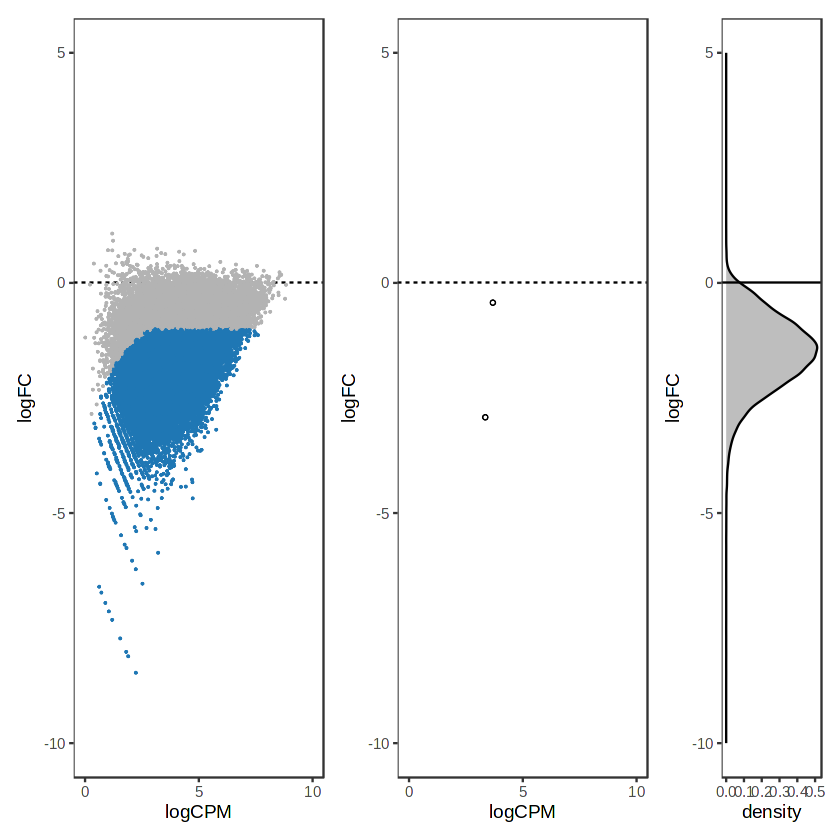

In [5]:
#write out plot
(p1 | p2 | p3) + plot_layout(widths=c(1,1,.4))
ggsave("panel_a_MA_density_t0.5.pdf", height=3)

# Counts of BAF-dep and -indep enhancers

In [7]:
#enumerate enhancers based on effects of BAFinh (down, not significant, and up)
DARs %>% filter(grepl("enh", type)) %>% group_by(change) %>% summarize(n=n())

change,n
<chr>,<int>
down,25039
nc,10006
